# 04: Model Architecture and Benchmarking

### Executive Summary & Decision Log
This notebook establishes the three-tier model progression and evaluates operational risk reduction across the mid-2024 through 2025 development validation partition ($N = 379$ days).

## Goals
Implement and evaluate the models:

1. **Evaluation**: Asymmetric pinball loss, directional decomposition(deficit vs. excess error), and physical tolerances (MAE/MAPE)
2. **Tier 0 Baseline**: Regularized Linear Quantile Regression with feature standardization.
3. **Tier 1 Models**: Independent single-task LightGBM quantile models benchmarked against symmetric MSE/MAE baselines.
4. **Tier 2 Architecture**: Physically structured chained quantile regressors

### Quantile Loss Levels
- **Ramp Magnitude ($\Delta MW_{norm}$)**: $\alpha = 0.85$ (Penalzie underprediction - Rather have extra spinning reserves)
- **Peak Ramp Speed ($S_{max}$)**: $\alpha = 0.85$ (Penalzie underprediction - Rather have extra spinning reserves)
- **Ramp Start Time ($t_{start}$)**: $\alpha = 0.15$ (Penalize overprediction - Rather predict an earlier start)
- **Ramp Duration ($\Delta t$)**: $\alpha = 0.50$ (Symmetric Loss - Unclear that this metric caries the same asymmetric risk)

## 1. Setup

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import QuantileRegressor
from sklearn.model_selection import KFold
import lightgbm as lgb


DATA_DIR = Path("./data")
print(f"Using data directory: {DATA_DIR.resolve()}")

Using data directory: C:\Users\evanh\Documents\Jupyter\energy-systems-analysis\data


## 2. Load Data and Split

- **Training Set**: 2021 through mid-2024
- **Validation Set**: mid-2024 through 2025 (used for hyperparameter tuning, model comparison, and early stopping)
- *(Holdout Test Set)*: 2026 data to be evaluated upon ingestion

In [3]:
data_path = DATA_DIR / "processed/features_selected.parquet"
df = pd.read_parquet(data_path)
df["date"] = pd.to_datetime(df["date"]).dt.date


target_configs = {
    "t_start_min": {"alpha": 0.15, "label": "Start Time (min past noon)", "unit": "min"},
    "delta_mw_norm": {"alpha": 0.85, "label": "Normalized Amplitude (MW/cap)", "unit": "norm"},
    "delta_t_min": {"alpha": 0.50, "label": "Duration (min)", "unit": "min"},
    "s_max": {"alpha": 0.85, "label": "Peak Speed (MW/min)", "unit": "MW/min"},
}
target_cols = list(target_configs.keys())


feature_cols = [c for c in df.columns if c not in ["date"] + target_cols]


print(f"Number NA rows: {df[feature_cols].isna().any(axis=1).sum()}")
df = df.dropna(subset=feature_cols).reset_index(drop=True)

# Date Partition (Train: 2021 through mid-2024, Val: mid-2024 through 2025)
split_date = pd.to_datetime("2024-07-01").date()
train_df = df[df["date"] < split_date].copy().reset_index(drop=True)
val_df = df[df["date"] >= split_date].copy().reset_index(drop=True)

print(f"Total features: {len(feature_cols)}")
print(f"Train samples:  {len(train_df):,} ({train_df['date'].min()} to {train_df['date'].max()})")
print(f"Val samples:    {len(val_df):,} ({val_df['date'].min()} to {val_df['date'].max()})")


Number NA rows: 1
Total features: 22
Train samples:  559 (2021-03-06 to 2024-06-29)
Val samples:    379 (2024-07-01 to 2025-12-22)


## 3. Evaluation Metrics Engine

Implements the Loss and Error function
1. **Pinball Loss**: $\mathcal{L}_\alpha(y, \hat{y}) = \max(\alpha(y - \hat{y}), (1 - \alpha)(\hat{y} - y))$
2. **Deficit Error** (Under-Prediction): $\max(0, y - \hat{y})$
3. **Excess Error** (Over-Prediction): $\max(0, \hat{y} - y)$
4. **Physical Tolerances**: MAE for $t_{start}, \Delta t, S_{max}$; MAPE for $\Delta MW_{norm}$
5. **Invariant Violation Rate**: $\mathbb{I}(\hat{S}_{max} < \bar{S})$ where $\bar{S} = \frac{\Delta \hat{MW}_{denorm}}{\Delta \hat{t}}$

In [ ]:
def pinball_loss(y_true, y_pred, alpha):
    """Empirical Pinball (Quantile) Loss."""
    err = np.asarray(y_true) - np.asarray(y_pred)
    return np.mean(np.maximum(alpha * err, (alpha - 1.0) * err))

def deficit_error(y_true, y_pred):
    """Mean defecit error (under-prediction)"""
    return np.mean(np.maximum(0.0, np.asarray(y_true) - np.asarray(y_pred)))

def excess_error(y_true, y_pred):
    """Mean excess error (over-prediction)"""
    return np.mean(np.maximum(0.0, np.asarray(y_pred) - np.asarray(y_true)))

def mae(y_true, y_pred):
    """Mean Absolute Error."""
    return np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)))

def mape(y_true, y_pred):
    """Mean Absolute Percentage Error (percentage units)."""
    y_t = np.asarray(y_true)
    return np.mean(np.abs((y_t - np.asarray(y_pred)) / np.clip(y_t, 1e-4, None))) * 100.0

def calculate_mean_ramp_speed(delta_mw_norm_pred, delta_t_pred, capacity_mw):
    """Computes physical average ramp speed"""
    delta_mw_denorm = np.asarray(delta_mw_norm_pred) * np.asarray(capacity_mw)
    delta_t_safe = np.clip(np.asarray(delta_t_pred), 15.0, None)  # Guard against zero/near-zero duration
    return delta_mw_denorm / delta_t_safe

def violation_rate(s_max_pred, s_bar):
    """Percentage of events violating the Mean Value Invariant (S_max < S_bar)."""
    return np.mean(np.asarray(s_max_pred) < np.asarray(s_bar)) * 100.0

def evaluate_envelope_predictions(y_true_df, y_pred_df, capacity_series):
    """Calculates evaluation summary across all targets."""
    summary = {}
    for target, config in target_configs.items():
        alpha = config["alpha"]
        yt = y_true_df[target].values
        yp = y_pred_df[target].values
        
        summary[f"{target}_pinball"] = pinball_loss(yt, yp, alpha)
        summary[f"{target}_deficit"] = deficit_error(yt, yp)
        summary[f"{target}_excess"] = excess_error(yt, yp)
        summary[f"{target}_mae"] = mae(yt, yp)
        if target == "delta_mw_norm":
            summary[f"{target}_mape"] = mape(yt, yp)
            
    # Compute Physical Mean Value Invariant violation rate
    s_bar_true = calculate_mean_ramp_speed(y_true_df["delta_mw_norm"], y_true_df["delta_t_min"], capacity_series)
    s_bar_pred = calculate_mean_ramp_speed(y_pred_df["delta_mw_norm"], y_pred_df["delta_t_min"], capacity_series)
    summary["violation_rate_pct"] = violation_rate(y_pred_df["s_max"], s_bar_pred)
    
    return pd.Series(summary)


## 4. Tier 0: Linear Quantile Regression Baseline

- Fits regularized linear quantile regression (`QuantileRegressor`) for each target dimension using target-specific $\alpha$.
- Preprocesses predictors with `StandardScaler` fitted strictly on `train_df`.

In [ ]:
# Preprocess features with StandardScaler fit on training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(train_df[feature_cols])
X_val_scaled = scaler.transform(val_df[feature_cols])

tier0_models = {}
tier0_val_preds = pd.DataFrame(index=val_df.index)

for target, config in target_configs.items():
    alpha = config["alpha"]

    reg = QuantileRegressor(quantile=alpha, alpha=1e-3)
    reg.fit(X_train_scaled, train_df[target])
    
    tier0_models[target] = reg
    tier0_val_preds[target] = reg.predict(X_val_scaled)

tier0_metrics = evaluate_envelope_predictions(val_df[target_cols], tier0_val_preds, val_df["total_solar_capacity_mw"])
print("--------Tier 0 Validation Performance ---------")
print(tier0_metrics)

=== Tier 0 Validation Performance ===
t_start_min_pinball       6.851141
t_start_min_deficit      21.469813
t_start_min_excess        4.271375
t_start_min_mae          25.741188
delta_mw_norm_pinball     0.026168
delta_mw_norm_deficit     0.024731
delta_mw_norm_excess      0.034314
delta_mw_norm_mae         0.059045
delta_mw_norm_mape       11.001787
delta_t_min_pinball      16.797626
delta_t_min_deficit      24.893984
delta_t_min_excess        8.701268
delta_t_min_mae          33.595252
s_max_pinball             1.812776
s_max_deficit             1.486961
s_max_excess              3.659058
s_max_mae                 5.146019
violation_rate_pct        0.000000
dtype: float64


## 5. Tier 1: Independent Single-Task LightGBM Regressors

- Fits four separate `LGBMRegressor` models under asymmetric pinball loss (`objective='quantile', alpha=alpha_k`).
- Fits four seperate models with symmetric loss (`objective='regression'` / MSE) to evaluate the  deficit/surplus tradeoff.

In [ ]:
lgb_params = {
    "n_estimators": 100,
    "learning_rate": 0.03,
    "max_depth": 4,
    "num_leaves": 12,
    "min_child_samples": 20,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": 42,
    "verbose": -1,
}
tier1_quantile_models = {}
tier1_symmetric_models = {}
tier1_quantile_preds = pd.DataFrame(index=val_df.index)
tier1_symmetric_preds = pd.DataFrame(index=val_df.index)

for target, config in target_configs.items():
    alpha = config["alpha"]
    
    # Asymmetric Quantile LightGBM
    q_model = lgb.LGBMRegressor(
        objective="quantile",
        alpha=alpha,
        **lgb_params
    )
    q_model.fit(train_df[feature_cols], train_df[target])
    tier1_quantile_models[target] = q_model
    tier1_quantile_preds[target] = q_model.predict(val_df[feature_cols])
    
    # Symmetric MSE LightGBM (Standard Baseline)
    s_model = lgb.LGBMRegressor(
        objective="regression",
        **lgb_params
    )
    s_model.fit(train_df[feature_cols], train_df[target])
    tier1_symmetric_models[target] = s_model
    tier1_symmetric_preds[target] = s_model.predict(val_df[feature_cols])
    
# Evaluate both on validation set
tier1_quantile_metrics = evaluate_envelope_predictions(
    val_df[target_cols], tier1_quantile_preds, val_df["total_solar_capacity_mw"]
)
tier1_symmetric_metrics = evaluate_envelope_predictions(
    val_df[target_cols], tier1_symmetric_preds, val_df["total_solar_capacity_mw"]
)
# Comparison Summary
comparison_df = pd.DataFrame({
    "Tier 0 (Linear Quantile)": tier0_metrics,
    "Tier 1 (Symmetric MSE)": tier1_symmetric_metrics,
    "Tier 1 (Quantile LightGBM)": tier1_quantile_metrics,
})

comparison_df

,Tier 0 (Linear Quantile),Tier 1 (Symmetric MSE),Tier 1 (Quantile LightGBM)
t_start_min_pinball,6.851141,12.797493,5.858246
t_start_min_deficit,21.469813,6.772302,21.881674
t_start_min_excess,4.271375,13.860762,3.030582
t_start_min_mae,25.741188,20.633063,24.912256
delta_mw_norm_pinball,0.026168,0.017975,0.024232
delta_mw_norm_deficit,0.024731,0.011931,0.000984
delta_mw_norm_excess,0.034314,0.052224,0.155970
delta_mw_norm_mae,0.059045,0.064155,0.156954
delta_mw_norm_mape,11.001787,12.524839,31.751659
delta_t_min_pinball,16.797626,13.073788,13.142762


## 6. Tier 2: Chained Quantile Regressors

- Implement chained models:
  1. $\hat{t}_{start} = f_1(\mathbf{x})$
  2. $\Delta \hat{MW}_{norm} = f_2(\mathbf{x}, \hat{t}_{start})$
  3. $\Delta \hat{t} = f_3(\mathbf{x}, \hat{t}_{start}, \Delta \hat{MW}_{norm})$
  4. $\hat{S}_{max} = f_4(\mathbf{x}, \hat{t}_{start}, \Delta \hat{MW}_{norm}, \Delta \hat{t}, \bar{S})$
- Uses 5-fold Out-Of-Fold (OOF) stacked predictions during training to avoid exposure bias.
- Applies post-processing projection: $\hat{S}_{max} \leftarrow \max(\hat{S}_{max}, \bar{S})$.

In [ ]:

# Initialize K-Fold splitter for out-of-fold training on train_df
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Containers for out-of-fold predictions during training
oof_preds = pd.DataFrame(index=train_df.index)


## T Start Model
oof_t_start = np.zeros(len(train_df))
for tr_idx, val_idx in kf.split(train_df):
    m1 = lgb.LGBMRegressor(objective="quantile", alpha=target_configs["t_start_min"]["alpha"], **lgb_params)
    m1.fit(train_df.iloc[tr_idx][feature_cols], train_df.iloc[tr_idx]["t_start_min"])
    oof_t_start[val_idx] = m1.predict(train_df.iloc[val_idx][feature_cols])

oof_preds["t_start_pred"] = oof_t_start
# Fit final full model for inference
f1_final = lgb.LGBMRegressor(objective="quantile", alpha=target_configs["t_start_min"]["alpha"], **lgb_params)
f1_final.fit(train_df[feature_cols], train_df["t_start_min"])

## Magnitude model
print("Fitting Tier 2 Chain: Step 2 (delta_mw_norm conditioned on t_start)...")
cols_f2 = feature_cols + ["t_start_pred"]
train_x2 = train_df[feature_cols].copy()
train_x2["t_start_pred"] = oof_preds["t_start_pred"]

oof_delta_mw = np.zeros(len(train_df))
for tr_idx, val_idx in kf.split(train_df):
    m2 = lgb.LGBMRegressor(objective="quantile", alpha=target_configs["delta_mw_norm"]["alpha"], **lgb_params)
    m2.fit(train_x2.iloc[tr_idx][cols_f2], train_df.iloc[tr_idx]["delta_mw_norm"])
    oof_delta_mw[val_idx] = m2.predict(train_x2.iloc[val_idx][cols_f2])

oof_preds["delta_mw_pred"] = oof_delta_mw
f2_final = lgb.LGBMRegressor(objective="quantile", alpha=target_configs["delta_mw_norm"]["alpha"], **lgb_params)
f2_final.fit(train_x2[cols_f2], train_df["delta_mw_norm"])

## Ramp Duration Model
print("Fitting Tier 2 Chain: Step 3 (delta_t conditioned on t_start, delta_mw)...")
cols_f3 = feature_cols + ["t_start_pred", "delta_mw_pred"]
train_x3 = train_x2.copy()
train_x3["delta_mw_pred"] = oof_preds["delta_mw_pred"]

oof_delta_t = np.zeros(len(train_df))
for tr_idx, val_idx in kf.split(train_df):
    m3 = lgb.LGBMRegressor(objective="quantile", alpha=target_configs["delta_t_min"]["alpha"], **lgb_params)
    m3.fit(train_x3.iloc[tr_idx][cols_f3], train_df.iloc[tr_idx]["delta_t_min"])
    oof_delta_t[val_idx] = m3.predict(train_x3.iloc[val_idx][cols_f3])

oof_preds["delta_t_pred"] = oof_delta_t
f3_final = lgb.LGBMRegressor(objective="quantile", alpha=target_configs["delta_t_min"]["alpha"], **lgb_params)
f3_final.fit(train_x3[cols_f3], train_df["delta_t_min"])

## Max Slope Model
print("Fitting Tier 2 Chain: Step 4 (s_max conditioned on envelope and S_bar)...")
oof_s_bar = calculate_mean_ramp_speed(
    oof_preds["delta_mw_pred"], oof_preds["delta_t_pred"], train_df["total_solar_capacity_mw"]
)
cols_f4 = feature_cols + ["t_start_pred", "delta_mw_pred", "delta_t_pred", "s_bar_pred"]
train_x4 = train_x3.copy()
train_x4["s_bar_pred"] = oof_s_bar
train_x4['delta_t_pred'] = oof_preds['delta_t_pred']

f4_final = lgb.LGBMRegressor(objective="quantile", alpha=target_configs["s_max"]["alpha"], **lgb_params)
f4_final.fit(train_x4[cols_f4], train_df["s_max"])


### Validation 
tier2_val_preds = pd.DataFrame(index=val_df.index)

#  Predict t_start
val_x1 = val_df[feature_cols].copy()
tier2_val_preds["t_start_min"] = f1_final.predict(val_x1)

# Predict delta_mw_norm conditioned on predicted t_start
val_x2 = val_x1.copy()
val_x2["t_start_pred"] = tier2_val_preds["t_start_min"]
tier2_val_preds["delta_mw_norm"] = f2_final.predict(val_x2[cols_f2])

#Predict delta_t_min conditioned on predicted t_start and delta_mw
val_x3 = val_x2.copy()
val_x3["delta_mw_pred"] = tier2_val_preds["delta_mw_norm"]
tier2_val_preds["delta_t_min"] = f3_final.predict(val_x3[cols_f3])

#Predict s_max conditioned on full predicted envelope and S_bar
val_s_bar = calculate_mean_ramp_speed(
    tier2_val_preds["delta_mw_norm"], tier2_val_preds["delta_t_min"], val_df["total_solar_capacity_mw"]
)
val_x4 = val_x3.copy()
val_x4["s_bar_pred"] = val_s_bar
val_x4['delta_t_pred'] = tier2_val_preds['delta_t_min']
tier2_raw_s_max = f4_final.predict(val_x4[cols_f4])

# Apply physical post-processing projection (S_max >= S_bar)
tier2_val_preds["s_max"] = np.maximum(tier2_raw_s_max, val_s_bar)

# Evaluate Tier 2
tier2_metrics = evaluate_envelope_predictions(
    val_df[target_cols], tier2_val_preds, val_df["total_solar_capacity_mw"]
)

#Tier 3 Scorecard
comparison_df["Tier 2 (Chained Quantile)"] = tier2_metrics
print("\n=== Final Three-Tier Benchmark Scorecard ===")
comparison_df


Fitting Tier 2 Chain: Step 1 (t_start)...
Fitting Tier 2 Chain: Step 2 (delta_mw_norm conditioned on t_start)...
Fitting Tier 2 Chain: Step 3 (delta_t conditioned on t_start, delta_mw)...
Fitting Tier 2 Chain: Step 4 (s_max conditioned on envelope and S_bar)...

=== Final Three-Tier Benchmark Scorecard ===


,Tier 0 (Linear Quantile),Tier 1 (Symmetric MSE),Tier 1 (Quantile LightGBM),Tier 2 (Chained Quantile)
t_start_min_pinball,6.851141,12.797493,5.858246,5.858246
t_start_min_deficit,21.469813,6.772302,21.881674,21.881674
t_start_min_excess,4.271375,13.860762,3.030582,3.030582
t_start_min_mae,25.741188,20.633063,24.912256,24.912256
delta_mw_norm_pinball,0.026168,0.017975,0.024232,0.024244
delta_mw_norm_deficit,0.024731,0.011931,0.000984,0.000976
delta_mw_norm_excess,0.034314,0.052224,0.155970,0.156096
delta_mw_norm_mae,0.059045,0.064155,0.156954,0.157072
delta_mw_norm_mape,11.001787,12.524839,31.751659,31.745825
delta_t_min_pinball,16.797626,13.073788,13.142762,13.129931


## 7. Model Benchmarking and Comparison

- Compare validation metrics across Tier 0, Tier 1, and Tier 2.
- Visualize predicted vs. actual ramp envelopes on sample validation days.

In [12]:
# Format comparison_df into a structured executive scorecard
scorecard_rows = [
    # Timing
    ("Ramp Start Time (t_start)", "Pinball Loss (alpha=0.15)", "t_start_min_pinball", "{:.2f}"),
    ("Ramp Start Time (t_start)", "Late Warning Error (min)", "t_start_min_excess", "{:.2f} min"),
    ("Ramp Start Time (t_start)", "MAE (min)", "t_start_min_mae", "{:.2f} min"),
    
    # Amplitude
    ("Ramp Amplitude (Delta MW)", "Pinball Loss (alpha=0.85)", "delta_mw_norm_pinball", "{:.4f}"),
    ("Ramp Amplitude (Delta MW)", "Generation Deficit Error", "delta_mw_norm_deficit", "{:.4f}"),
    ("Ramp Amplitude (Delta MW)", "MAE (MW/cap)", "delta_mw_norm_mae", "{:.4f}"),
    ("Ramp Amplitude (Delta MW)", "MAPE (%)", "delta_mw_norm_mape", "{:.1f}%"),
    
    # Duration
    ("Ramp Duration (Delta t)", "Pinball Loss (alpha=0.50)", "delta_t_min_pinball", "{:.2f}"),
    ("Ramp Duration (Delta t)", "MAE (min)", "delta_t_min_mae", "{:.2f} min"),
    
    # Peak Speed
    ("Peak Speed (S_max)", "Pinball Loss (alpha=0.85)", "s_max_pinball", "{:.2f}"),
    ("Peak Speed (S_max)", "Deficit Shortfall (MW/min)", "s_max_deficit", "{:.2f} MW/min"),
    ("Peak Speed (S_max)", "MAE (MW/min)", "s_max_mae", "{:.2f} MW/min"),
    
    # Physics Invariant
    ("Physical Consistency", "Mean Value Violations (S_max < S_bar)", "violation_rate_pct", "{:.1f}%"),
]

formatted_records = []
for target_group, metric_label, metric_key, fmt in scorecard_rows:
    record = {"Target": target_group, "Metric": metric_label}
    for col in comparison_df.columns:
        val = comparison_df.loc[metric_key, col]
        record[col] = fmt.format(val)
    formatted_records.append(record)

scorecard_table = pd.DataFrame(formatted_records).set_index(["Target", "Metric"])
display(scorecard_table)


Tier 0 (Linear Quantile)  \
Target                    Metric                                                           
Ramp Start Time (t_start) Pinball Loss (alpha=0.15)                                 6.85   
                          Late Warning Error (min)                              4.27 min   
                          MAE (min)                                            25.74 min   
Ramp Amplitude (Delta MW) Pinball Loss (alpha=0.85)                               0.0262   
                          Generation Deficit Error                                0.0247   
                          MAE (MW/cap)                                            0.0590   
                          MAPE (%)                                                 11.0%   
Ramp Duration (Delta t)   Pinball Loss (alpha=0.50)                                16.80   
                          MAE (min)                                            33.60 min   
Peak Speed (S_max)        Pinball Loss (alpha=0.85)                                 1.81   
                          Deficit Shortfall (MW/min)                         1.49 MW/min   
                          MAE (MW/min)                                       5.15 MW/min   
Physical Consistency      Mean Value Violations (S_max < S_bar)                     0.0%   

                                                                Tier 1 (Symmetric MSE)  \
Target                    Metric                                                         
Ramp Start Time (t_start) Pinball Loss (alpha=0.15)                              12.80   
                          Late Warning Error (min)                           13.86 min   
                          MAE (min)                                          20.63 min   
Ramp Amplitude (Delta MW) Pinball Loss (alpha=0.85)                             0.0180   
                          Generation Deficit Error                              0.0119   
                          MAE (MW/cap)                                          0.0642   
                          MAPE (%)                                               12.5%   
Ramp Duration (Delta t)   Pinball Loss (alpha=0.50)                              13.07   
                          MAE (min)                                          26.15 min   
Peak Speed (S_max)        Pinball Loss (alpha=0.85)                               3.01   
                          Deficit Shortfall (MW/min)                       3.33 MW/min   
                          MAE (MW/min)                                     4.57 MW/min   
Physical Consistency      Mean Value Violations (S_max < S_bar)                   0.0%   

                                                                Tier 1 (Quantile LightGBM)  \
Target                    Metric                                                             
Ramp Start Time (t_start) Pinball Loss (alpha=0.15)                                   5.86   
                          Late Warning Error (min)                                3.03 min   
                          MAE (min)                                              24.91 min   
Ramp Amplitude (Delta MW) Pinball Loss (alpha=0.85)                                 0.0242   
                          Generation Deficit Error                                  0.0010   
                          MAE (MW/cap)                                              0.1570   
                          MAPE (%)                                                   31.8%   
Ramp Duration (Delta t)   Pinball Loss (alpha=0.50)                                  13.14   
                          MAE (min)                                              26.29 min   
Peak Speed (S_max)        Pinball Loss (alpha=0.85)                                   2.05   
                          Deficit Shortfall (MW/min)                           1.81 MW/min   
                          MAE (MW/min)                                         5.24 MW/min   
Physical Consist

C:\Users\evanh\AppData\Local\Temp\ipykernel_5404\2110339185.py:42: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  act_t_start = noon_time + pd.Timedelta(minutes=actual_row["t_start_min"])
C:\Users\evanh\AppData\Local\Temp\ipykernel_5404\2110339185.py:43: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  act_t_peak = act_t_start + pd.Timedelta(minutes=actual_row["delta_t_min"])
C:\Users\evanh\AppData\Local\Temp\ipykernel_5404\2110339185.py:47: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  pred_

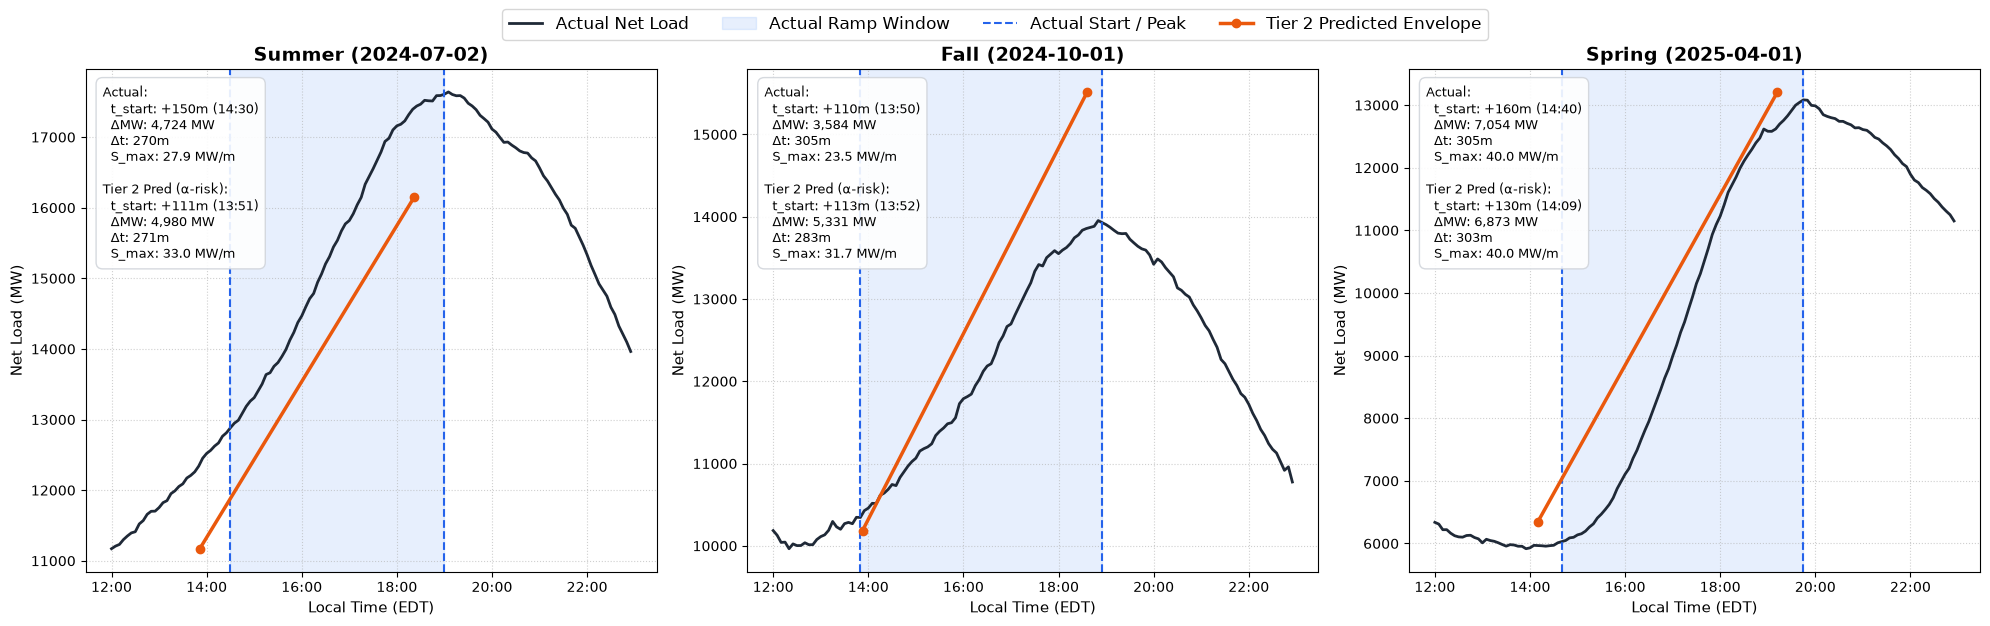

In [ ]:
import matplotlib.dates as mdates

# Load telemetry for y-true
telemetry_path = DATA_DIR / "processed/telemetry_5min.parquet"
telemetry_df = pd.read_parquet(telemetry_path)

# Ensure local datetime
if telemetry_df["interval_start_local"].dt.tz is None:
    telemetry_df["interval_start_local"] = telemetry_df["interval_start_local"].dt.tz_localize("US/Eastern")
telemetry_df["date"] = telemetry_df["interval_start_local"].dt.date

# Select 3 representative validation dates across seasons
sample_dates = [
    pd.to_datetime("2024-07-02").date(),  # Summer high solar
    pd.to_datetime("2024-10-01").date(),  # Fall transition
    pd.to_datetime("2025-04-01").date(),  # Spring peak duck curve
]

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=False)

for ax, sample_date in zip(axes, sample_dates):
    # Filter 5-minute telemetry for afternoon window (12:00 PM to 10:00 PM)
    day_mask = (
        (telemetry_df["date"] == sample_date)
        & (telemetry_df["interval_start_local"].dt.hour >= 12)
        & (telemetry_df["interval_start_local"].dt.hour <= 22)
    )
    day_telem = telemetry_df[day_mask].sort_values("interval_start_local").copy()
    if day_telem.empty:
        continue
    
    # Extract actuals and predictions
    actual_row = val_df[val_df["date"] == sample_date].iloc[0]
    val_idx = val_df[val_df["date"] == sample_date].index[0]
    pred_row = tier2_val_preds.loc[val_idx]
    
    capacity = actual_row["total_solar_capacity_mw"]
    noon_time = day_telem["interval_start_local"].iloc[0]
    base_net_load = day_telem["net_load"].iloc[0]
    
    # Actual timing and amplitude
    act_t_start = noon_time + pd.Timedelta(minutes=actual_row["t_start_min"])
    act_t_peak = act_t_start + pd.Timedelta(minutes=actual_row["delta_t_min"])
    act_delta_mw = actual_row["delta_mw_norm"] * capacity
    
    # Predicted timing and amplitude (Tier 2)
    pred_t_start = noon_time + pd.Timedelta(minutes=pred_row["t_start_min"])
    pred_t_peak = pred_t_start + pd.Timedelta(minutes=pred_row["delta_t_min"])
    pred_delta_mw = pred_row["delta_mw_norm"] * capacity
    
    # Plot actual 5-min net load curve
    ax.plot(
        day_telem["interval_start_local"],
        day_telem["net_load"],
        color="#1f2937",
        linewidth=2,
        label="Actual Net Load",
    )
    
    # Shading actual event duration
    ax.axvspan(
        act_t_start,
        act_t_peak,
        color="#3b82f6",
        alpha=0.12,
        label="Actual Ramp Window",
    )
    ax.axvline(act_t_start, color="#2563eb", linestyle="--", linewidth=1.5, label="Actual Start / Peak")
    ax.axvline(act_t_peak, color="#2563eb", linestyle="--", linewidth=1.5)
    
    # Draw Predicted Envelope Box / Vector (Tier 2 Chained)
    ax.plot(
        [pred_t_start, pred_t_peak],
        [base_net_load, base_net_load + pred_delta_mw],
        color="#ea580c",
        linestyle="-",
        linewidth=2.5,
        marker="o",
        label="Tier 2 Predicted Envelope",
    )
    
    # Formatting
    season_name = "Summer" if sample_date.month == 7 else ("Fall" if sample_date.month == 10 else "Spring")
    ax.set_title(f"{season_name} ({sample_date})", fontsize=14, fontweight="bold")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=day_telem["interval_start_local"].dt.tz))
    ax.set_xlabel("Local Time (EDT)", fontsize=11)
    ax.set_ylabel("Net Load (MW)", fontsize=11)
    ax.grid(True, linestyle=":", alpha=0.6)
    
    # Info Box
    info_text = (
        f"Actual:\n"
        f"  t_start: +{actual_row['t_start_min']:.0f}m ({act_t_start.strftime('%H:%M')})\n"
        f"  ΔMW: {act_delta_mw:,.0f} MW\n"
        f"  Δt: {actual_row['delta_t_min']:.0f}m\n"
        f"  S_max: {actual_row['s_max']:.1f} MW/m\n\n"
        f"Tier 2 Pred (α-risk):\n"
        f"  t_start: +{pred_row['t_start_min']:.0f}m ({pred_t_start.strftime('%H:%M')})\n"
        f"  ΔMW: {pred_delta_mw:,.0f} MW\n"
        f"  Δt: {pred_row['delta_t_min']:.0f}m\n"
        f"  S_max: {pred_row['s_max']:.1f} MW/m"
    )
    ax.text(
        0.03,
        0.97,
        info_text,
        transform=ax.transAxes,
        fontsize=9.5,
        verticalalignment="top",
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="#d1d5db", alpha=0.9),
    )

# Single legend for the entire figure
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.05), ncol=4, fontsize=12)
plt.tight_layout()
plt.show()
